## EDA de los datasets ##

El presente notebook tiene como intención el realizar una analisis exploratorio de los datos que serán utilizados para los modelos del proyecto. Buscamos definir: variables de entrada y su naturaleza, variable objetivo, decisiones a tomar para la transformación de los datos.

# Importación de bibliotecas y datos

In [2]:
# Importación de bibliotecas
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import seaborn as sns
import os
import kagglehub
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, confusion_matrix
import mlflow
import mlflow.sklearn
import argparse

In [3]:
#Importación de datos

# Definir la ruta a la carpeta de datos procesados
processed_dir = Path("../data/processed")

# Buscar todos los archivos Parquet de viajes usando glob
parquet_files = sorted(processed_dir.glob("trips_*.parquet"))

# Lista temporal para guardar los DataFrames de cada mes
df_list = []

# Ciclo for para leer cada archivo y agregarlo a la lista
for file_path in parquet_files:
  print(f"Cargando: {file_path.name}")
  temp_df = pd.read_parquet(file_path)
  df_list.append(temp_df)

# Unir todos los DataFrames en uno solo grande
df_trips_all = pd.concat(df_list, ignore_index=True)

# Cargar el catálogo de estaciones
df_stations = pd.read_parquet(processed_dir / "stations.parquet")

print("\n¡Carga completa!")
print(f"Total de registros combinados: {df_trips_all.shape}")
df_trips_all.head()
print(f"Total de estaciones: {df_stations.shape}")

Cargando: trips_2024_01.parquet
Cargando: trips_2024_02.parquet
Cargando: trips_2024_03.parquet
Cargando: trips_2024_04.parquet
Cargando: trips_2024_05.parquet
Cargando: trips_2024_06.parquet
Cargando: trips_2024_07.parquet
Cargando: trips_2024_08.parquet
Cargando: trips_2024_09.parquet
Cargando: trips_2024_10.parquet
Cargando: trips_2024_11.parquet
Cargando: trips_2024_12.parquet
Cargando: trips_2025_01.parquet
Cargando: trips_2025_02.parquet
Cargando: trips_2025_03.parquet
Cargando: trips_2025_04.parquet
Cargando: trips_2025_05.parquet
Cargando: trips_2025_06.parquet
Cargando: trips_2025_07.parquet
Cargando: trips_2025_08.parquet
Cargando: trips_2025_09.parquet
Cargando: trips_2025_10.parquet
Cargando: trips_2025_11.parquet
Cargando: trips_2025_12.parquet

¡Carga completa!
Total de registros combinados: (9177953, 5)
Total de estaciones: (484, 5)


# Exploración de los datos

Iniciamos con la visualización de algunos datos, ver los campos y el tipo de dato

In [11]:
#Hacemos una info() de nuestras variables para ver el tipo de dato y si hay nulos
print('Información de viajes:')
df_trips_all.info()

print('Información de estaciones:')
df_stations.info() 

Información de viajes:
<class 'pandas.DataFrame'>
RangeIndex: 9177953 entries, 0 to 9177952
Data columns (total 5 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   trip_id                 string        
 1   start_time              datetime64[us]
 2   end_time                datetime64[us]
 3   origin_station_id       string        
 4   destination_station_id  string        
dtypes: datetime64[us](2), string(3)
memory usage: 464.4 MB
Información de estaciones:
<class 'pandas.DataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    484 non-null    string 
 1   station_name  484 non-null    string 
 2   latitude      484 non-null    float64
 3   longitude     484 non-null    float64
 4   capacity      484 non-null    int64  
dtypes: float64(2), int64(1), string(2)
memory usage: 40.2 KB


df_trips_all

- Vemos que hay unos datos identificados como origin_station_id y destination_station_id que están como string en el dataframe  y por su nombre son identificadores, por lo tanto deben de ser datos integer. Podría requerirse una transformación de ese tipo de dato. 

df_stations
- También se observa una variable de nombre station_id que se ve que es tipo string pero es un identificador, debe de ser cambiado a tipo integer. 

In [10]:
# Hacemos un head para ver como se estructura cada data set

print('Primeros registros de viajes:')
display(df_trips_all.head())

print('Primeros registros de estaciones:')
display(df_stations.head())

Primeros registros de viajes:


,trip_id,start_time,end_time,origin_station_id,destination_station_id
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154


Primeros registros de estaciones:


,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


df_trips_all
- Podemos obtener información del tiempo de duración del viaje usando el start_time y el end_time
- Podemos obtener información de comportamiento de los viajes como:¿De que estacion salen los viajes? ¿Hay rutas tipicas? Ej: salen de la estación 1 para llegar a la 10
    
df_stations_head
 - Es un data set de catálogo solamente, no tiene información de registros
 - Al combinar esta info con la de df_trips_all podríamos obtener información como la ubicación de origen y ubicación de fin


In [4]:
#Hacemos un describe para ver las variables

df_trips_all.describe()

,start_time,end_time
count,9177953,9177953
mean,2024-12-24 18:26:05.186699,2024-12-24 18:36:34.892584
min,2024-01-01 00:05:25,2024-01-01 00:16:37
25%,2024-06-13 14:39:15,2024-06-13 14:49:17
50%,2024-12-24 10:58:30,2024-12-24 11:08:06
75%,2025-06-27 11:45:55,2025-06-27 11:56:33
max,2025-12-31 23:59:08,2026-01-01 00:09:47


Vamos a realizar gráficas descriptivas para que nos permitan visualizar comportamiento de los datos

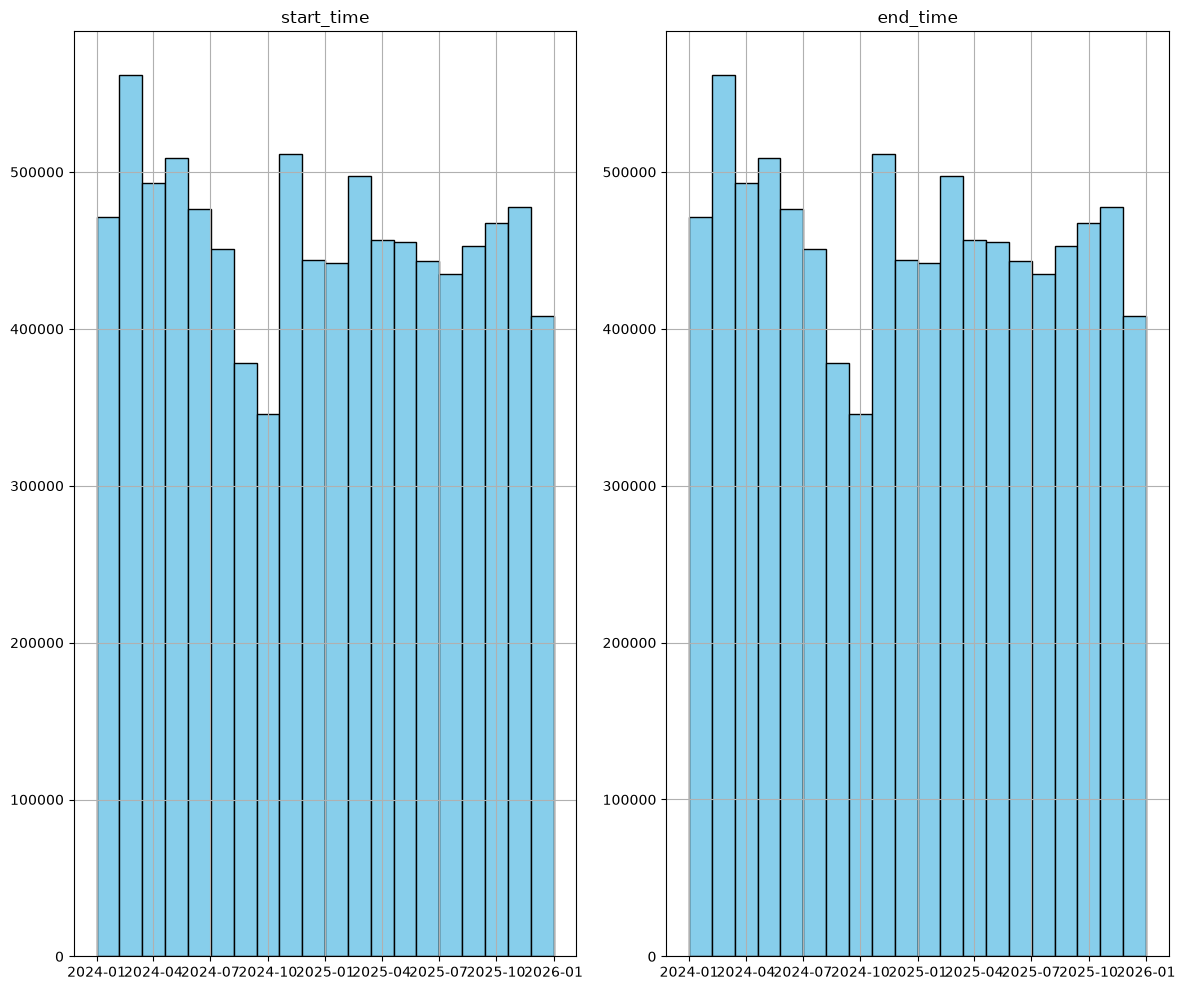

In [12]:
# Genera histogramas para todas las columnas numéricas del DataFrame
df_trips_all.hist(bins=20, figsize=(12, 10), color='skyblue', edgecolor='black')

plt.tight_layout()
plt.show()

Estos primeros histogramas no nos arrojan mucha información sobre comportamiento. Vamos a agregar unos campos nuevos al df_trips_all que nos permita realizar un mejor analisis. 

- Año: año de inicio
- Mes: Mes de inicio
- Dia: Dia de inicio
- Dia_semana: dia de la semana de inicio
- duracion_viaje: tiempo en minutos de duración del viaje. 

In [16]:
#Agregamos las variables nuevas


# Adicionamos campos de tiempo
df_trips_all["Año"] = df_trips_all["start_time"].dt.year
df_trips_all["Mes"] = df_trips_all["start_time"].dt.month
df_trips_all["Dia"] = df_trips_all["start_time"].dt.day
df_trips_all["Dia_semana"] = df_trips_all["start_time"].dt.weekday

# Calcular la duración del viaje en minutos
df_trips_all["duracion_viaje"] = (
    df_trips_all["end_time"] - df_trips_all["start_time"]
).dt.total_seconds() / 60.0

df_trips_all.head()

,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,2024,1,1,0,24.200000
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,2024,1,1,0,9.233333
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,2024,1,1,0,9.100000
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,2024,1,1,0,23.916667
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,2024,1,1,0,23.700000


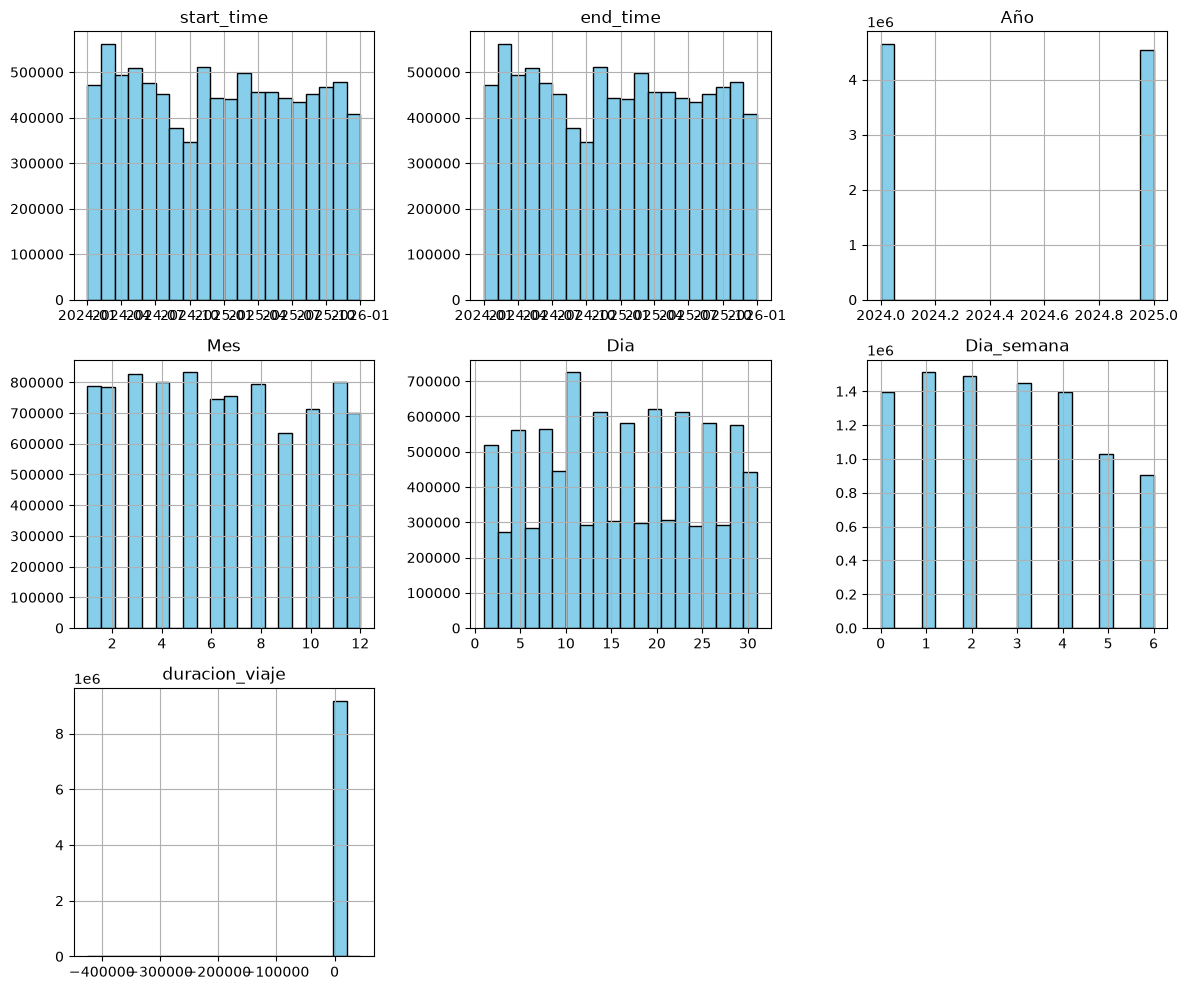

In [17]:
# Genera histogramas para todas las columnas numéricas del DataFrame
df_trips_all.hist(bins=20, figsize=(12, 10), color='skyblue', edgecolor='black')

plt.tight_layout()
plt.show()

De este análisis podemos ver que hay algunos comportamientos a señalar: 
- Los días con más uso son entre el 1 y 3, de Martes  a Jueves. El fin de semana el uso baja drásticamente. 
- Vemos esa misma estancionalidad en la gráfica por día del mes, hay un bajón cada fin de semana, pero también hay una tendencia a que en la mitad del mes es una epoca de uso alto. 
- En cuanto a los meses, si hay una reducción de uso a partir del mes 8, pudiendose ver afectado por el otoño-invierno. 
- En el 2025 hubo una reducción en el uso con respecto a 2024. Sin embargo, dos periodos es una ventana de tiempo muy corta para determinar una tendencia en reducción de uso. 

Sobre el tiempo de duración, se realizará un boxplot para analizar si hay datos atipicos

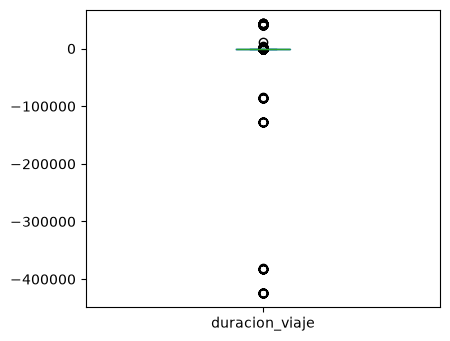

In [18]:
df_trips_all["duracion_viaje"].plot(
    kind='box', 
    subplots=True, 
    layout=(3, 3), 
    figsize=(12, 10), 
    sharex=False, 
    sharey=False
)

plt.tight_layout()
plt.show()

In [23]:
# Filtrar los viajes con una duración menor a 0 minutos
df_negativos = df_trips_all[df_trips_all['duracion_viaje'] < 0]

# Ver cuántos registros cumplen con esta condición y mostrar los primeros
print(f'Total de viajes menores a 0 minutos: {len(df_negativos):,}')

print('Primeros registros de viajes con duración negativa:')
display(df_negativos.head())

Total de viajes menores a 0 minutos: 115
Primeros registros de viajes con duración negativa:


,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
3270148,35593231,2024-12-09 23:39:00,2024-09-13 00:00:00,55,257,2024,12,9,0,-126699.0
3270150,35593233,2024-12-09 23:39:00,2024-09-13 00:00:00,55,257,2024,12,9,0,-126699.0
3270152,35593235,2024-12-09 23:39:00,2024-09-13 00:02:00,55,257,2024,12,9,0,-126697.0
3270153,35593236,2024-12-09 23:40:00,2024-09-13 00:04:00,289,12,2024,12,9,0,-126696.0
3270158,35593243,2024-12-09 23:41:00,2024-09-13 00:03:00,58,33,2024,12,9,0,-126698.0


Vemos que hay unos datos que tienen un tiempo de inicio mayor al final, lo que indica que por calculo el viaje tendria una duracion negativa. 

Son 115 registros de 9177953, representando el 0.0012%. Se propone eliminar estos registros, pudiendo tener errores de registro en otros campos. 

In [25]:
df_trips_limpio = df_trips_all[df_trips_all['start_time'] <= df_trips_all['end_time']].copy()

print(f'Total de viajes antes de limpiar los registros con duración negativa: {len(df_trips_all):,}')
print(f'Total de viajes después de limpiar los registros con duración negativa: {len(df_trips_limpio):,}')

Total de viajes antes de limpiar los registros con duración negativa: 9,177,953
Total de viajes después de limpiar los registros con duración negativa: 9,177,838


Revisión de duplicados

In [33]:
# Verificar si hay registros duplicados y si fuera así, elimínalos del dataframe.

duplicate_rows = df_trips_limpio[df_trips_limpio.duplicated()].index #Guardo en un array los index de los registros duplicados
longitud_antes = df_trips_limpio.shape[0]
print('Antes de eliminar duplicados:',longitud_antes)
print('Tenemos:',len(duplicate_rows),'registros duplicados')
df_trips_limpio = df_trips_limpio.drop(index= duplicate_rows) #Elimino los renglones que se repiten
longitud_despues = df_trips_limpio.shape[0]
print('Después de eliminar duplicados:',longitud_despues)

#Reinicio el index por si eliminó columnas

df_trips_limpio = df_trips_limpio.reset_index(drop=True) #Reinicio el index

Antes de eliminar duplicados: 9177838
Tenemos: 0 registros duplicados
Después de eliminar duplicados: 9177838


# Propuesta de dataframe final

Considerando la información contenida en el data frame "df_trips_limpio" y la información del catálogo de df_stations se realiza la propuesta de generar un data frame final enriquecido con la información geográfica y de capacidades de las estaciones de origen y destino

In [27]:
df_stations.head()

,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [28]:
df_trips_limpio.head()

,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,2024,1,1,0,24.200000
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,2024,1,1,0,9.233333
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,2024,1,1,0,9.100000
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,2024,1,1,0,23.916667
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,2024,1,1,0,23.700000


In [32]:
# Realizar los merges para enriquecer el dataset de viajes con la información de las estaciones de origen y destino

# Merge para obtener los datos de la estación de ORIGEN
df_merged = df_trips_all.merge(
    df_stations[['station_id', 'latitude', 'longitude', 'capacity']],  # <-- Incluimos 'station_id aquí'
    left_on='origin_station_id',
    right_on='station_id',
    how='left'
).rename(columns={
    'latitude': 'origin_latitude',
    'longitude': 'origin_longitude',
    'capacity': 'origin_capacity'
}).drop(columns=['station_id']) # Limpiamos la columna auxiliar del id de estación

# Merge para obtener los datos de la estación de DESTINO
df_merged = df_merged.merge(
    df_stations[['station_id', 'latitude', 'longitude', 'capacity']],  # <-- Incluimos 'station_id' aquí también
    left_on='destination_station_id',
    right_on='station_id',
    how='left'
).rename(columns={
    'latitude': 'destination_latitude',
    'longitude': 'destination_longitude',
    'capacity': 'destination_capacity'
}).drop(columns=['station_id']) # Limpiamos de nuevo la columna auxiliar

# Resultado: Un dataset enriquecido con la información espacial y estructural completa
print(f"Dimensiones del dataset final enriquecido: {df_merged.shape}")
df_merged.head()

Dimensiones del dataset final enriquecido: (9177953, 16)


,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje,origin_latitude,origin_longitude,origin_capacity,destination_latitude,destination_longitude,destination_capacity
0,31789291,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271,2024,1,1,0,24.200000,20.734410,-103.380790,19,20.68504,-103.347960,31
1,31789292,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254,2024,1,1,0,9.233333,20.686050,-103.354080,15,20.67848,-103.365103,15
2,31789293,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254,2024,1,1,0,9.100000,20.686050,-103.354080,15,20.67848,-103.365103,15
3,31789294,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154,2024,1,1,0,23.916667,20.677419,-103.347983,15,20.69493,-103.373330,15
4,31789295,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154,2024,1,1,0,23.700000,20.677419,-103.347983,15,20.69493,-103.373330,15
